# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Maleah Caboteja, Jaden Otchere, Jalen Medley

**Date:** Nov 5th

In [ ]:
# Your Phase 1 solution to the problem goes here.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('./data/pierce_county_house_sales.csv')

# data cleaning and investigation

# print(df.isnull().sum().sort_values(ascending=False))
# print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

missing_percent = (df.isnull().mean() * 100).sort_values(ascending=False)
# print(missing_percent[missing_percent > 0])
missing = ['waterfront_type', 'view_quality', 'roof_cover', 'interior', 'hvac_description', 'exterior']
for col in missing:
    df[col] = df[col].fillna('Unknown')
# print(df.isnull().sum().sort_values(ascending=False))

zero_rooms = df[(df['bedrooms'] == 0) | (df['bathrooms'] == 0)]
# print("Number of observations:", len(zero_rooms))
# display(zero_rooms[['sale_price', 'bedrooms', 'bathrooms',
#                     'house_square_feet', 'year_built']])


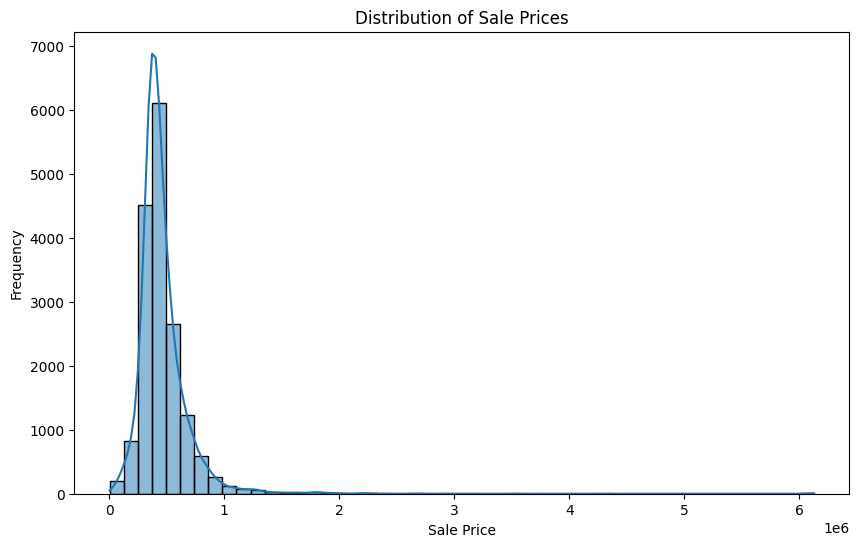

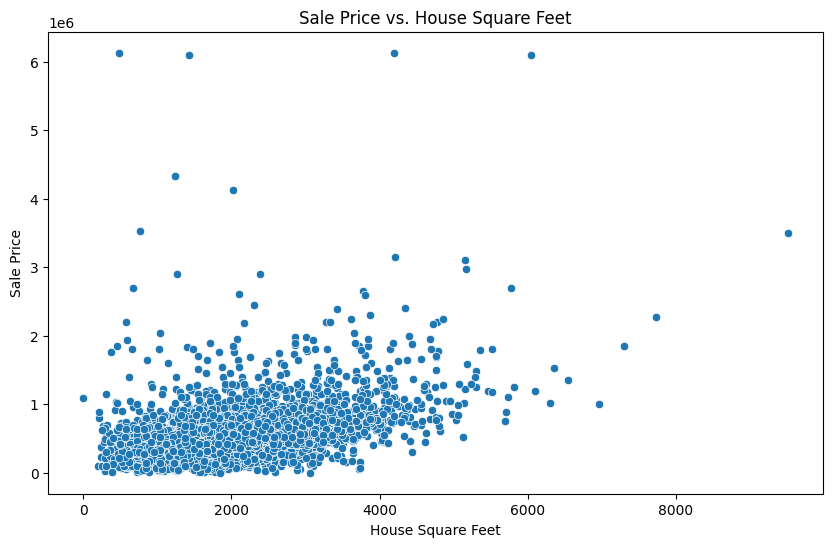

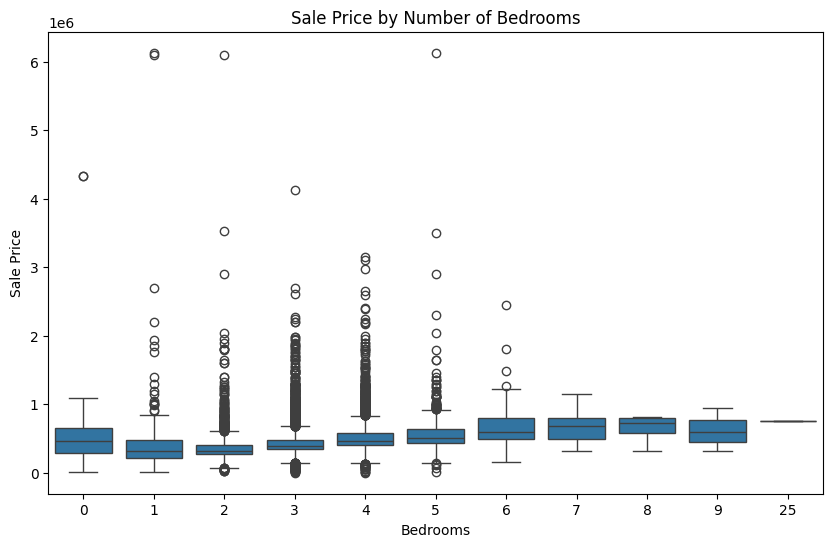

In [17]:
# visualizations
plt.figure(figsize=(10, 6))
sns.histplot(df['sale_price'], bins=50, kde=True)
plt.title('Distribution of Sale Prices')
plt.xlabel('Sale Price')
plt.ylabel('Frequency')
plt.show()

plt.figure(figsize=(10, 6))
sns.scatterplot(x='house_square_feet', y='sale_price', data=df)
plt.title('Sale Price vs. House Square Feet')
plt.xlabel('House Square Feet')
plt.ylabel('Sale Price')
plt.show()

plt.figure(figsize=(10, 6))
sns.boxplot(x='bedrooms', y='sale_price', data=df)
plt.title('Sale Price by Number of Bedrooms')
plt.xlabel('Bedrooms')
plt.ylabel('Sale Price')
plt.show()


In [ ]:
# categorical 
from sklearn.model_selection import train_test_split
df['sale_date'] = pd.to_datetime(df['sale_date'])
df['sale_year'] = df['sale_date'].dt.year
df['sale_month'] = df['sale_date'].dt.month
df = df.drop(columns=['sale_date'])

X = df.drop(columns=['sale_price'])
y = df['sale_price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
categorical_cols = X_train.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()
X_test = pd.get_dummies(X_test, columns=categorical_cols, drop_first=True)
X_train = pd.get_dummies(X_train, columns=categorical_cols, drop_first=True)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Test target shape:", y_test.shape)

print(X_train.select_dtypes(include=['object', 'category']).columns.tolist())
print(X_train.isnull().sum().sum())
print(X_test.isnull().sum().sum())

Training set shape: (13414, 60)
Test set shape: (3354, 60)
Training target shape: (13414,)
Test target shape: (3354,)
[]
0
0


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]